# 仅 P 开启共享 G2
读取最新完成的全量结果，导出汇总及对照图。原始报告仅流式读取，不修改。

In [1]:
from pathlib import Path
import json
import ijson
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.home() / 'project/aisimulate/experiments/disk'
CASE = 'p_g2_shared'
OUT = ROOT / 'analysis' / CASE / 'assets'
OUT.mkdir(parents=True, exist_ok=True)
RUN_DIR = None  # 可指定某次运行目录；None 自动选最新完成的全量运行
REFRESH = False
if RUN_DIR is None:
    results = Path.home() / 'project/results'
    pattern = 'glm52-1p1d/*/run.json' if CASE == 'hbm_only' else f'glm52-1p1d-g2/*/{CASE}/*/run.json'
    candidates = []
    for path in results.glob(pattern):
        meta = json.loads(path.read_text())
        if meta.get('status') != 'completed' or meta.get('max_requests') != 0:
            continue
        # 避免将单组入口运行的 G2 误认为 HBM-only。
        if CASE == 'hbm_only':
            import yaml
            cfg = yaml.safe_load((path.parent/'resolved.yaml').read_text())
            if any('host_offload' in w['kv_cache'] for w in cfg['engine']['workers'].values()):
                continue
        candidates.append(path.parent)
    if not candidates:
        raise FileNotFoundError(f'{CASE} 没有已完成的全量结果')
    RUN_DIR = sorted(candidates, key=lambda p: p.name)[-1]
RUN_DIR = Path(RUN_DIR).expanduser().resolve()
report = RUN_DIR / 'prediction/prediction.json'
stat = report.stat()
fingerprint = {'path': str(report), 'bytes': stat.st_size, 'mtime_ns': stat.st_mtime_ns}
cache = OUT/'summary.json'
previous = json.loads(cache.read_text()) if cache.exists() else {}
if not REFRESH and previous.get('source') == fingerprint:
    summary = previous
else:
    metrics = {}
    domains = []
    with report.open('rb') as stream:
        for prefix, event, value in ijson.parse(stream):
            if '.' not in prefix and prefix and event in ('number', 'string', 'boolean', 'null'):
                metrics[prefix] = float(value) if event == 'number' else value
            if prefix == 'g2_domains.item' and event == 'start_map':
                domains.append({})
            if prefix.startswith('g2_domains.item.') and event == 'number':
                domains[-1][prefix.rsplit('.', 1)[-1]] = float(value)
    meta = json.loads((RUN_DIR/'run.json').read_text())
    summary = {'experiment': CASE, 'source': fingerprint, 'run': meta,
               'metrics': metrics, 'g2_domains': domains}
    cache.write_text(json.dumps(summary, ensure_ascii=False, indent=2))
m = summary['metrics']
row = {'experiment': CASE, 'requests': int(m['num_requests']),
       'completed': int(m['completed_requests']), 'sla_pass': int(m['goodput_completed_requests']),
       'sla_pass_percent': 100*m['goodput_completed_requests']/m['num_requests'],
       'mean_ttft_s': m['mean_ttft_ms']/1000, 'p95_ttft_s': m['p95_ttft_ms']/1000,
       'p99_ttft_s': m['p99_ttft_ms']/1000, 'mean_itl_ms': m['mean_itl_ms'],
       'max_token_gap_s': m['max_itl_ms']/1000,
       'mean_e2e_s': m['mean_e2e_latency_ms']/1000,
       'prefix_reuse_percent': 100*m['prefix_cache_reused_ratio']}
pd.DataFrame([row]).to_csv(OUT/'metrics.csv', index=False)
print('原始结果：', RUN_DIR)
print(pd.DataFrame([row]).to_string(index=False))


原始结果： /home/xieqiang/project/results/glm52-1p1d-g2/20261105T094503.158905Z/p_g2_shared/20261105T094520.729529Z
 experiment  requests  completed  sla_pass  sla_pass_percent  mean_ttft_s  p95_ttft_s  p99_ttft_s  mean_itl_ms  max_token_gap_s  mean_e2e_s  prefix_reuse_percent
p_g2_shared    665415     665415    628365         94.432046     1.405225    5.926506   19.463899    13.006726       477.843739    7.401231             95.407375


  experiment  requests  completed  sla_pass  sla_pass_percent  mean_ttft_s  p95_ttft_s  p99_ttft_s  mean_itl_ms  max_token_gap_s  mean_e2e_s  prefix_reuse_percent
    hbm_only    665415     665415    608828         91.495984     3.464018   11.390399   64.721150    13.039210       196.284861    9.475000             94.317075
 p_g2_shared    665415     665415    628365         94.432046     1.405225    5.926506   19.463899    13.006726       477.843739    7.401231             95.407375
pd_g2_shared    665415     665415    628709         94.483743     1.380438    5.838243   19.248169    12.999479       367.075221    7.373103             95.407485


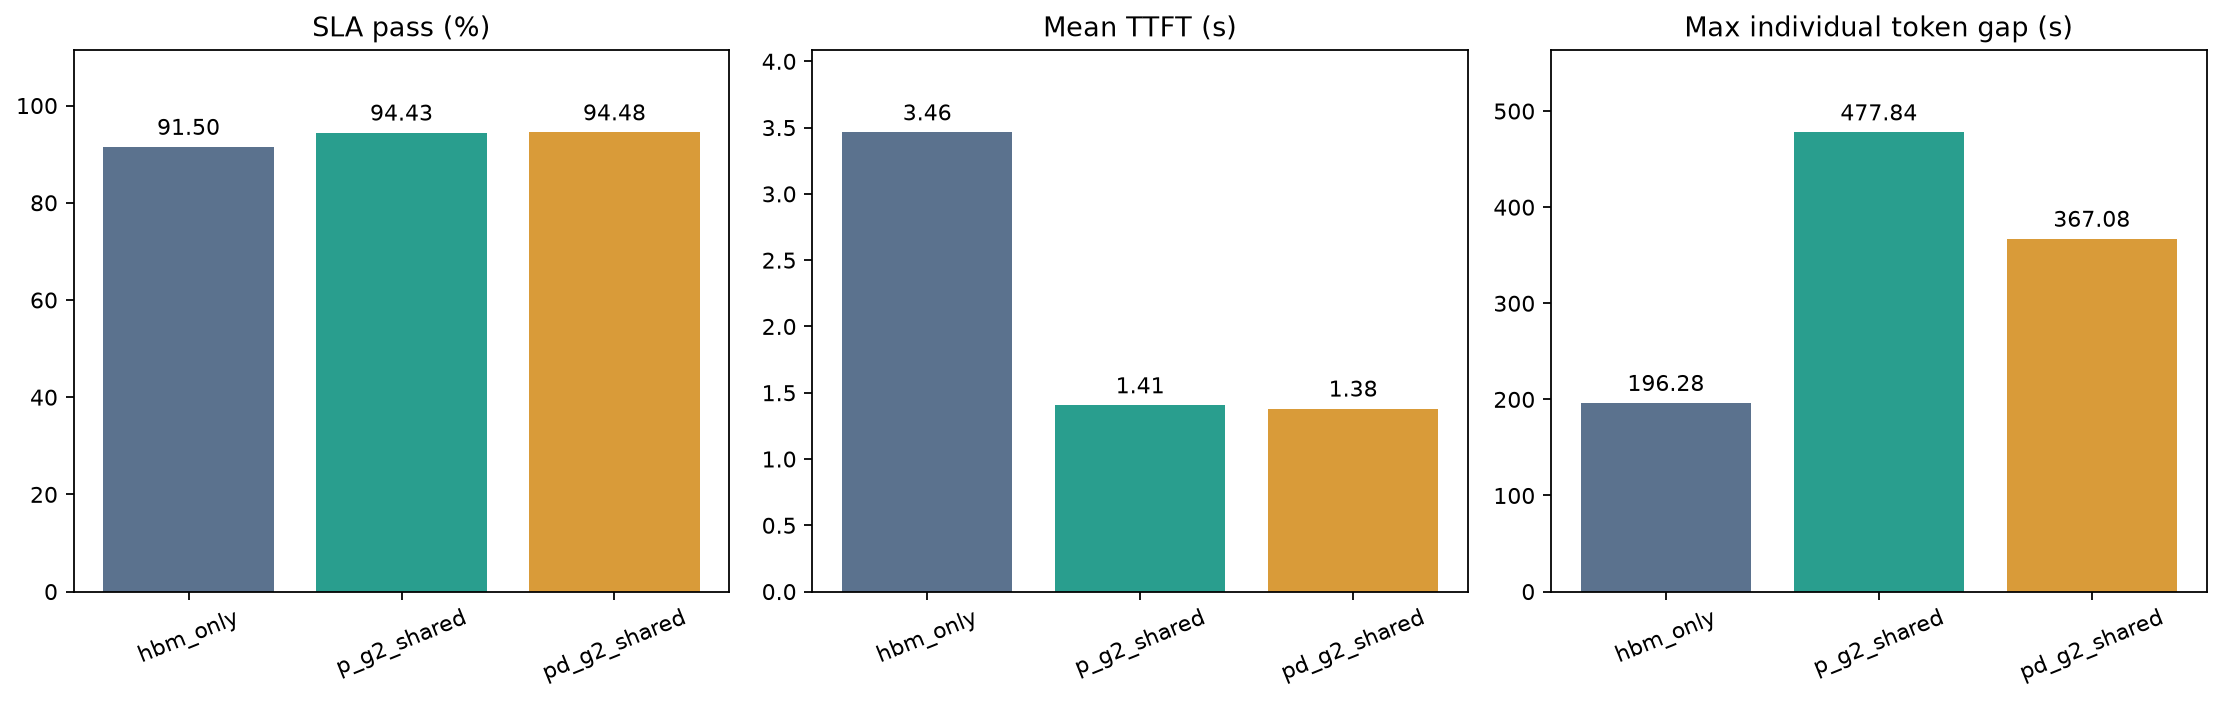

In [2]:
# 对比所有已生成的汇总；缺少其他实验时先运行其他 Notebook。
rows = []
sources = {}
for case in ['hbm_only', 'p_g2_shared', 'pd_g2_shared']:
    folder = ROOT/'analysis'/case / 'assets'
    path = folder/'metrics.csv'
    if path.exists():
        rows.extend(pd.read_csv(path).to_dict('records'))
        sources[case] = json.loads((folder/'summary.json').read_text())['source']
frame = pd.DataFrame(rows)
frame.to_csv(OUT/'comparison.csv', index=False)
(OUT/'comparison.json').write_text(json.dumps({'sources': sources, 'rows': rows}, ensure_ascii=False, indent=2))
print(frame.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, key, title in zip(axes, ['sla_pass_percent','mean_ttft_s','max_token_gap_s'],
                         ['SLA pass (%)','Mean TTFT (s)','Max individual token gap (s)']):
    bars = ax.bar(frame['experiment'], frame[key], color=['#5b728e','#299e8e','#d99b39'][:len(frame)])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=22)
    ax.set_ylim(0, max(frame[key])*1.18)
    ax.bar_label(bars, fmt='%.2f', padding=3)
fig.tight_layout()
fig.savefig(OUT/'comparison.png', dpi=160, bbox_inches='tight')
plt.show()


## 长停顿分析
扫描重新准入、定位最大间隔候选请求并导出分钟级负载。候选区间不等于精确 token 时间戳；代码不会自动修改手写归因。

重新准入请求数： 192 平均 ITL>50ms： 57
满足必要条件的候选请求： 13 其中重新准入： 1
    session_id                      arrival_utc  input_length  output_length     itl_ms  generation_span_ms  readmission_count  first_token_ms  last_token_ms
request_457534 2026-08-17T15:21:03.170000+00:00        112094            830 595.372943       493564.169612                  1    8.002628e+09   8.003121e+09


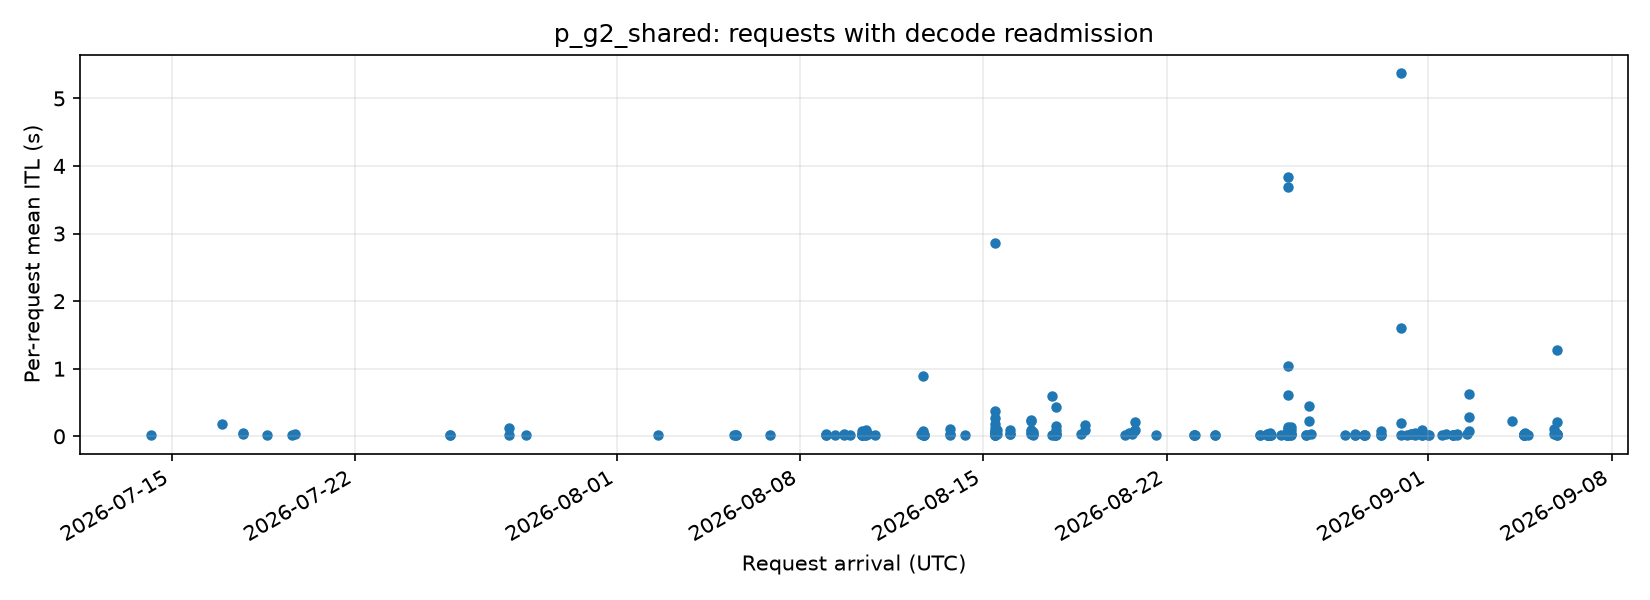

In [3]:
# 长停顿诊断：逐请求均值不能直接定位全局最大单次 token 间隔。
import datetime as dt
from collections import Counter
import heapq
report_dir = Path(summary['source']['path']).parent
with (Path(summary['run']['bundle'])/'source_requests.jsonl').open() as f:
    first_source = json.loads(f.readline())
with (report_dir/'requests.jsonl').open() as f:
    first_record = json.loads(f.readline())
origin_ms = first_source['start_ms'] - first_record['arrival_time_ms']
def utc(ms):
    return dt.datetime.fromtimestamp((origin_ms+ms)/1000, dt.timezone.utc).isoformat()
max_gap = m['max_itl_ms']
readmitted = []
possible = []
matched = []
minute = {}
counts = Counter()
# 固定关联请求，用相同 session_id 比较三组；这是trace序号，不是源agent会话。
ids = {'request_415432','request_457534','request_595423','request_595428'}
with (report_dir/'requests.jsonl').open() as stream:
    for line in stream:
        x = json.loads(line)
        start = x.get('first_token_ms')
        end = x.get('last_token_ms')
        x['generation_span_ms'] = end-start if start is not None and end is not None else 0
        x['arrival_utc'] = utc(x['arrival_time_ms'])
        counts['requests'] += 1
        counts['readmitted_requests'] += int(x['readmission_count'] > 0)
        counts['average_itl_over_50ms'] += int((x.get('itl_ms') or 0)>50)
        if x['readmission_count']:
            readmitted.append(x)
        # 必要条件；正常长输出也可能满足，不能自动认定它包含最大间隔。
        if x['generation_span_ms'] >= max_gap:
            possible.append(x)
        if x.get('session_id') in ids:
            matched.append(x)
        bucket = int(x['arrival_time_ms']//60000)
        row = minute.setdefault(bucket, {'minute':bucket, 'utc':utc(bucket*60000),
            'arrivals':0, 'long_input_64k':0, 'input_tokens':0, 'decode_admissions':0})
        row['arrivals'] += 1
        row['long_input_64k'] += int(x['input_length']>=65536)
        row['input_tokens'] += x['input_length']
        if x.get('decode_admit_ms') is not None:
            bucket = int(x['decode_admit_ms']//60000)
            row = minute.setdefault(bucket, {'minute':bucket, 'utc':utc(bucket*60000),
                'arrivals':0,'long_input_64k':0,'input_tokens':0,'decode_admissions':0})
            row['decode_admissions'] += 1
suspects = [x for x in possible if x['readmission_count']]
# 首token/重新准入之间的时段是候选区间，不是精确token停顿区间。
for x in suspects:
    history = [a for a in x['admission_history'] if a['pool']=='decode']
    x['decode_readmission_intervals'] = []
    previous = x['first_token_ms']
    for a in history:
        if a['is_readmission']:
            x['decode_readmission_intervals'].append({'start_bound_utc':utc(previous),
                'readmit_utc':utc(a['at_ms']), 'elapsed_ms':a['at_ms']-previous,
                'reused_input_tokens':a['reused_input_tokens']})
            previous = a['at_ms']
evidence = {'case':CASE,'source':summary['source'],'utc_origin_ms':origin_ms,
            'max_individual_gap_ms':max_gap,'counts':dict(counts),
            'candidate_rule':'generation span >= global max individual gap; not exact attribution',
            'possible_request_count':len(possible),'readmitted_candidates':suspects,
            'matched_requests':matched,
            'limitations':'No per-token timestamps or pressure events retained; exact max-gap pair and eviction trigger cannot be reconstructed.'}
(OUT/'stall_analysis.json').write_text(json.dumps(evidence,ensure_ascii=False,indent=2))
(OUT/'stall_readmissions.json').write_text(json.dumps(readmitted,ensure_ascii=False,indent=2))
(OUT/'stall_candidates.json').write_text(json.dumps(possible,ensure_ascii=False,indent=2))
columns = ['session_id','arrival_utc','input_length','output_length','itl_ms',
           'generation_span_ms','readmission_count','first_token_ms','last_token_ms']
pd.DataFrame(possible).reindex(columns=columns).to_csv(OUT/'stall_candidates.csv',index=False)
pd.DataFrame(matched).reindex(columns=columns).to_csv(OUT/'stall_matched_requests.csv',index=False)
pd.DataFrame(sorted(minute.values(),key=lambda x:x['minute'])).to_csv(OUT/'stall_load_minutes.csv',index=False)
print('重新准入请求数：', counts['readmitted_requests'], '平均 ITL>50ms：',counts['average_itl_over_50ms'])
print('满足必要条件的候选请求：',len(possible),'其中重新准入：',len(suspects))
print(pd.DataFrame(suspects).reindex(columns=columns).to_string(index=False))
# 仅绘制重新准入请求的平均ITL，不冒充单次token间隔。
fig, ax = plt.subplots(figsize=(11,4))
if readmitted:
    xs=[dt.datetime.fromisoformat(x['arrival_utc']) for x in readmitted]
    ax.scatter(xs,[(x.get('itl_ms') or 0)/1000 for x in readmitted],s=16)
ax.set_title(CASE+': requests with decode readmission')
ax.set_ylabel('Per-request mean ITL (s)')
ax.set_xlabel('Request arrival (UTC)')
ax.grid(alpha=.25)
fig.autofmt_xdate();fig.tight_layout()
fig.savefig(OUT/'stall_readmissions.png',dpi=150)
plt.show()


  experiment        request                      arrival_utc  input_length  output_length     ttft_s  mean_itl_ms  readmissions
    hbm_only request_415432 2026-08-12T16:41:56.901000+00:00         75504           1422 100.645640   153.306039             1
    hbm_only request_457534 2026-08-17T15:21:03.170000+00:00        112094            830  32.671045    16.787311             0
    hbm_only request_595423 2026-08-30T23:04:01.460000+00:00         95684            233  31.215890    19.247877             0
    hbm_only request_595428 2026-08-30T23:04:17.328000+00:00         97135             69  17.703883    20.013648             0
 p_g2_shared request_415432 2026-08-12T16:41:56.901000+00:00         75504           1422  86.977151    19.169904             0
 p_g2_shared request_457534 2026-08-17T15:21:03.170000+00:00        112094            830  23.842153   595.372943             1
 p_g2_shared request_595423 2026-08-30T23:04:01.460000+00:00         95684            233  24.056408  15

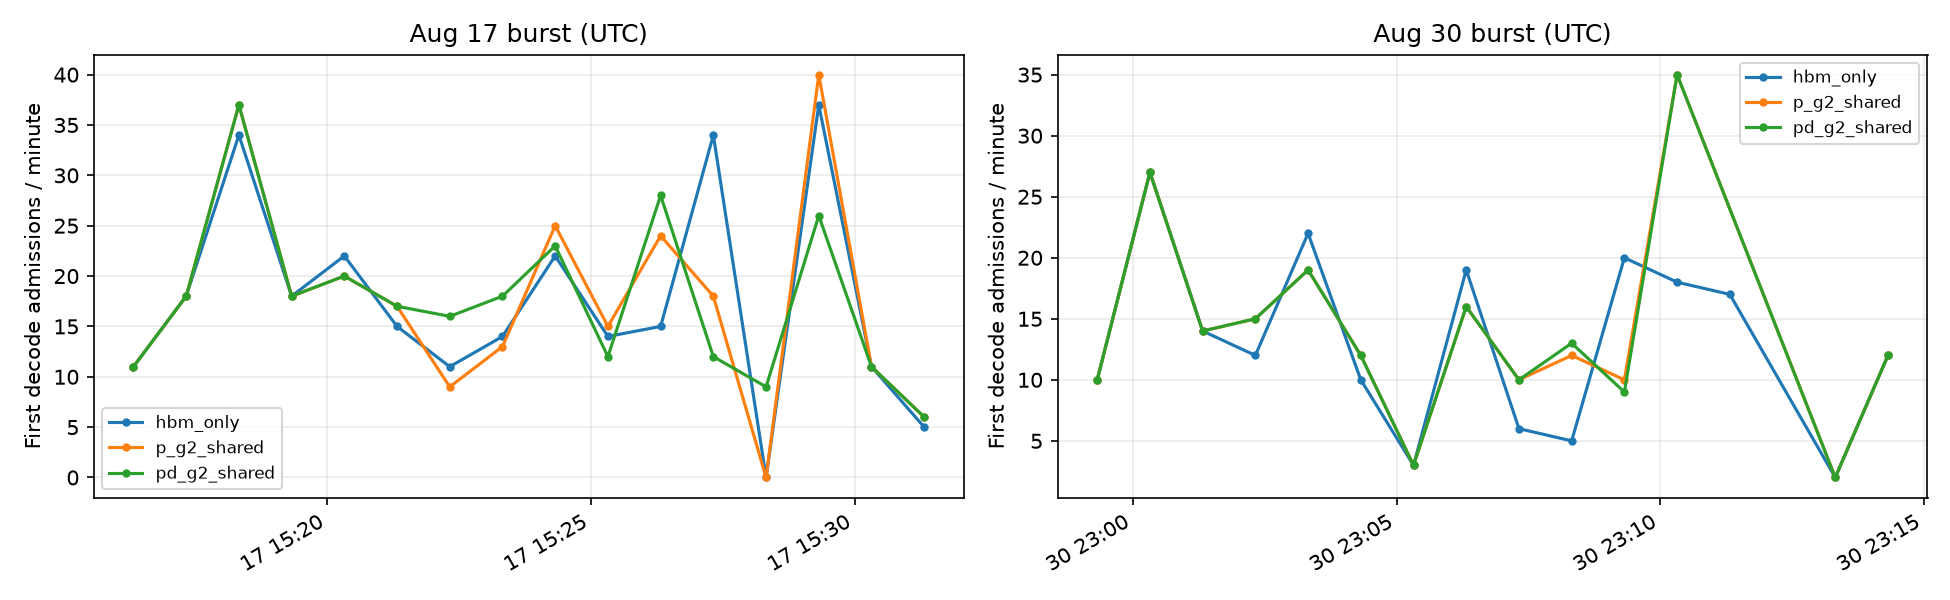

In [4]:
# 同一请求与相同时段对照；三个Notebook的长停顿单元运行后再执行本单元。
comparison_rows=[]
series={}
for case in ['hbm_only','p_g2_shared','pd_g2_shared']:
    folder=ROOT/'analysis'/case / 'assets'
    p=folder/'stall_analysis.json'
    if not p.exists(): continue
    evidence=json.loads(p.read_text())
    for x in evidence['matched_requests']:
        comparison_rows.append({'experiment':case,'request':x['session_id'],
            'arrival_utc':x['arrival_utc'],'input_length':x['input_length'],'output_length':x['output_length'],
            'ttft_s':x['ttft_ms']/1000,'mean_itl_ms':x['itl_ms'],'readmissions':x['readmission_count']})
    series[case]=pd.read_csv(folder/'stall_load_minutes.csv')
table=pd.DataFrame(comparison_rows)
table.to_csv(OUT/'stall_comparison.csv',index=False)
(OUT/'stall_comparison.json').write_text(json.dumps(comparison_rows,ensure_ascii=False,indent=2))
print(table.to_string(index=False))
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,anchor,title in zip(axes,[8002620000,9153600000],['Aug 17 burst (UTC)','Aug 30 burst (UTC)']):
    for case,frame in series.items():
        chosen=frame[(frame['minute']*60000>=anchor-300000)&(frame['minute']*60000<=anchor+600000)]
        ax.plot(pd.to_datetime(chosen['utc']),chosen['decode_admissions'],marker='.',label=case)
    ax.set_title(title);ax.set_ylabel('First decode admissions / minute');ax.legend(fontsize=8);ax.grid(alpha=.25)
fig.autofmt_xdate();fig.tight_layout();fig.savefig(OUT/'stall_load_comparison.png',dpi=150)
plt.show()
